# Segmentation de clients bancaires avec K-means

**Objectif business** : une banque portugaise appelle ses clients pour leur vendre un **dépôt à terme**. Seuls ~11 % acceptent. Peut-on regrouper les clients en **segments homogènes** pour adapter l'offre et ne plus appeler tout le monde de la même façon ?

**Démarche**
1. Explorer les données
2. Construire des variables qui décrivent le *client*
3. Choisir le nombre de segments *k*
4. Entraîner K-means et interpréter les segments
5. Vérifier si les segments se comportent différemment (taux de souscription)
6. En tirer des recommandations commerciales

*Données* : [Bank Marketing, UCI](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro, Cortez & Rita, 2014), 41 188 clients, licence CC BY 4.0.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # pour importer src/ depuis notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from src import segmentation as seg

pd.set_option("display.precision", 3)
%matplotlib inline

## 1. Exploration des données

In [2]:
df = seg.charger_donnees()
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# La cible : a-t-il souscrit au dépôt à terme ?  -> données déséquilibrées
df["y"].value_counts(normalize=True)

y
no     0.887
yes    0.113
Name: proportion, dtype: float64

In [4]:
# Variables catégorielles clés
for col in ["job", "education", "marital", "default", "housing", "loan"]:
    print(col, "->", df[col].value_counts().head(6).to_dict())

job -> {'admin.': 10422, 'blue-collar': 9254, 'technician': 6743, 'services': 3969, 'management': 2924, 'retired': 1720}
education -> {'university.degree': 12168, 'high.school': 9515, 'basic.9y': 6045, 'professional.course': 5243, 'basic.4y': 4176, 'basic.6y': 2292}
marital -> {'married': 24928, 'single': 11568, 'divorced': 4612, 'unknown': 80}
default -> {'no': 32588, 'unknown': 8597, 'yes': 3}
housing -> {'yes': 21576, 'no': 18622, 'unknown': 990}
loan -> {'no': 33950, 'yes': 6248, 'unknown': 990}


**À retenir**
- `default = unknown` concerne ~21 % des clients : la banque ne connaît pas leur historique de crédit. C'est en soi une information.
- `duration` (durée de l'appel) n'est connue qu'**après** l'appel : on l'exclut, sinon on « triche ».
- Les variables macro (`euribor3m`, `emp.var.rate`…) décrivent le contexte économique, pas le client : exclues de la segmentation.

## 2. Variables de segmentation

In [5]:
X = seg.construire_variables(df)
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
age,40.024,10.421,17.0,98.0
niveau_etudes,4.154,1.604,0.0,6.0
emploi_qualifie,0.558,0.497,0.0,1.0
retraite,0.042,0.200,0.0,1.0
etudiant,0.021,0.144,0.0,1.0
marie,0.605,0.489,0.0,1.0
credit_immo,0.524,0.499,0.0,1.0
credit_conso,0.152,0.359,0.0,1.0
defaut_inconnu,0.209,0.406,0.0,1.0
deja_contacte,0.137,0.343,0.0,1.0


K-means calcule des **distances** : sans mise à l'échelle, l'âge (17 à 98) écraserait les variables 0/1. On **centre-réduit** donc chaque variable (moyenne 0, écart-type 1).

In [6]:
Z, scaler = seg.standardiser(X)
Z.mean(axis=0).round(2), Z.std(axis=0).round(2)

(array([-0.,  0.,  0.,  0., -0., -0.,  0., -0., -0.,  0.]),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]))

## 3. Choisir le nombre de segments k

In [7]:
scores = seg.evaluer_k(Z, k_min=2, k_max=10)
scores

,k,inertie,silhouette
0,2,350801.536,0.184
1,3,303946.216,0.203
2,4,272698.576,0.219
3,5,231854.565,0.221
4,6,207026.558,0.214
5,7,183389.758,0.233
6,8,165415.236,0.244
7,9,157012.329,0.243
8,10,148489.941,0.250


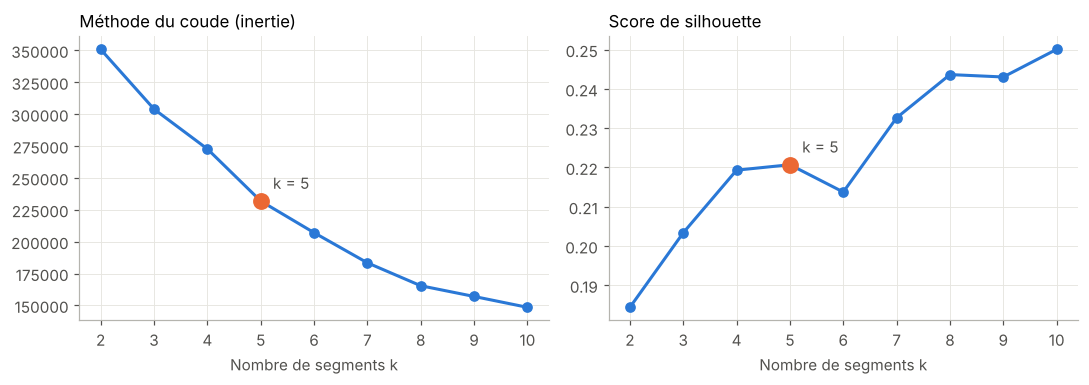

In [8]:
seg.figure_choix_k(scores, k_retenu=5);

**Pourquoi k = 5 ?**
- La courbe d'inertie forme un **coude** autour de 4-5 : au-delà, chaque segment en plus apporte moins.
- La silhouette a un **premier pic local à k = 5**. Elle remonte ensuite (k = 8-10), mais en découpant des segments en sous-groupes difficiles à exploiter.
- Côté métier, **5 segments** restent gérables par une équipe marketing : chacun peut recevoir une offre dédiée.

Le choix de k n'est jamais purement statistique : c'est un compromis entre qualité mathématique et **utilité business**.

## 4. Entraîner K-means et interpréter les segments

In [9]:
km = seg.entrainer_kmeans(Z, k=5)
profils = seg.profiler_segments(df, X, km.labels_)
profils[["nom", "nb_clients", "part_clients", "age", "niveau_etudes", "emploi_qualifie",
         "marie", "defaut_inconnu", "deja_contacte", "souscription"]]

,nom,nb_clients,part_clients,age,niveau_etudes,emploi_qualifie,marie,defaut_inconnu,deja_contacte,souscription
segment,,,,,,,,,,
0,Jeunes étudiants,875,0.021,25.895,4.206,0.000,0.047,1.189e-01,0.321,0.314
4,Seniors retraités,1720,0.042,62.027,3.252,0.000,0.741,2.285e-01,0.226,0.252
2,Actifs qualifiés,19407,0.471,38.314,5.093,1.000,0.540,7.214e-04,0.151,0.129
1,Actifs employés / ouvriers,11100,0.269,38.630,3.157,0.024,0.646,0.000e+00,0.137,0.094
3,Clients peu documentés,8086,0.196,42.890,3.457,0.408,0.737,1.000e+00,0.063,0.049


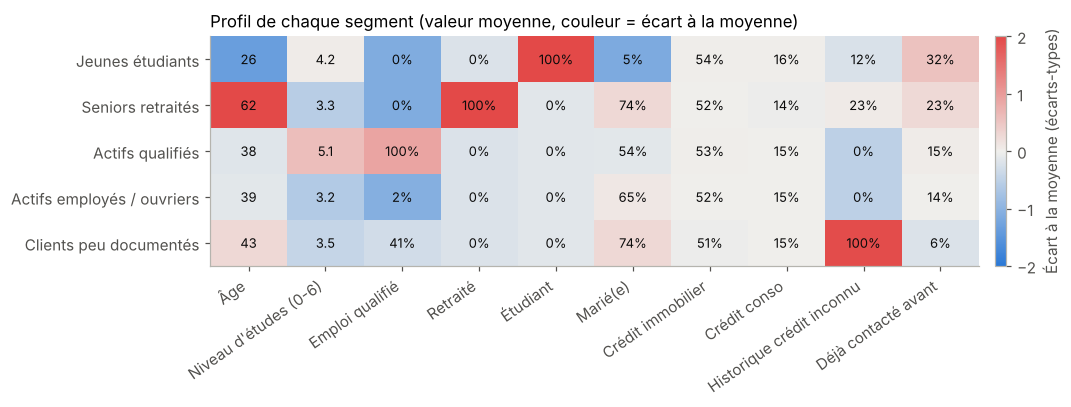

In [10]:
seg.figure_profils(X, profils);

**Lecture** : rouge = au-dessus de la moyenne, bleu = en dessous.
- **Jeunes étudiants** (26 ans) : célibataires, souvent déjà contactés par la banque.
- **Seniors retraités** (62 ans) : moins diplômés, plus souvent mariés.
- **Actifs qualifiés** : le cœur de clientèle (47 %), le plus diplômé.
- **Actifs employés / ouvriers** : emplois peu qualifiés, niveau d'études plus bas.
- **Clients peu documentés** : historique de crédit inconnu, rarement contactés auparavant.

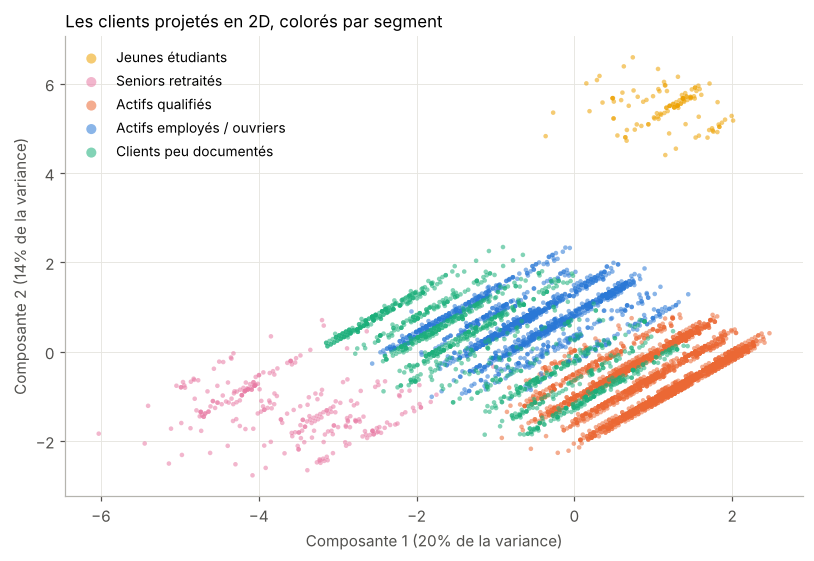

In [11]:
seg.figure_pca(Z, km.labels_, profils);

L'ACP résume les 10 variables en 2 axes (34 % de la variance). Étudiants et retraités sont **bien isolés** ; les trois segments d'actifs se chevauchent davantage, ce qui est logique : ils diffèrent surtout sur des variables 0/1.

## 5. Les segments prédisent-ils la souscription ?

La variable `y` **n'a pas servi** à construire les segments. Si leurs taux de souscription diffèrent nettement, la segmentation a une vraie valeur commerciale.

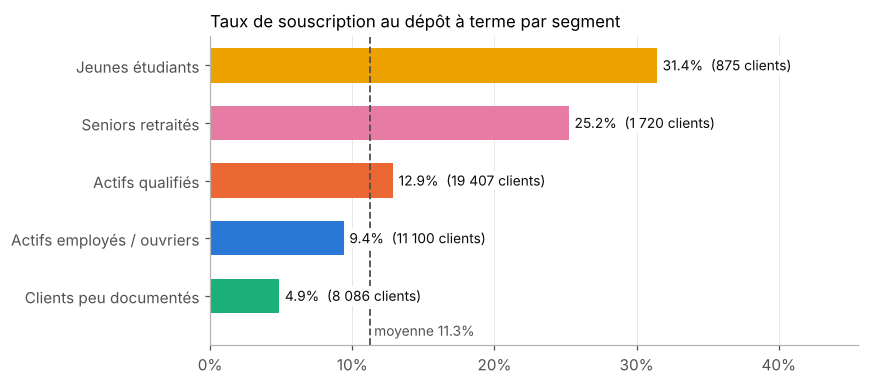

In [12]:
taux_global = (df["y"] == "yes").mean()
seg.figure_souscription(profils, taux_global);

In [13]:
profils[["nom", "nb_clients", "souscription", "lift"]]

,nom,nb_clients,souscription,lift
segment,,,,
0,Jeunes étudiants,875,0.314,2.790
4,Seniors retraités,1720,0.252,2.240
2,Actifs qualifiés,19407,0.129,1.141
1,Actifs employés / ouvriers,11100,0.094,0.834
3,Clients peu documentés,8086,0.049,0.431


**Résultat clé** : les étudiants souscrivent **2,8 fois plus** que la moyenne, les retraités **2,2 fois plus**, alors que les clients peu documentés souscrivent **2,3 fois moins**.

Exemple chiffré : si la banque n'appelait plus le segment « peu documentés » (20 % des clients), elle économiserait 1 appel sur 5 en ne perdant qu'environ 8 % des souscriptions.

In [14]:
d = profils.set_index("nom")
part_appels = d.loc["Clients peu documentés", "part_clients"]
part_souscr = (d["nb_clients"] * d["souscription"]).loc["Clients peu documentés"] / (d["nb_clients"] * d["souscription"]).sum()
print(f"Appels économisés : {part_appels:.0%}  |  souscriptions perdues : {part_souscr:.0%}")

Appels économisés : 20%  |  souscriptions perdues : 8%


## 6. Recommandations business

In [15]:
reco = seg.tableau_recommandations(profils)
for _, r in reco.iterrows():
    print(f"■ {r['nom']}  ({r['nb_clients']} clients, souscription {r['souscription']:.1%})")
    print(f"  {r['recommandation']}\n")

■ Jeunes étudiants  (875 clients, souscription 31.4%)
  Taux de souscription le plus élevé. Proposer un livret épargne jeune avec versements programmés, via l'app mobile et les partenariats écoles. Enjeu long terme : fidéliser avant le premier emploi.

■ Seniors retraités  (1720 clients, souscription 25.2%)
  Forte appétence pour l'épargne sécurisée. Conseiller dédié, dépôt à terme, assurance-vie et transmission. Contact téléphonique ou agence.

■ Actifs qualifiés  (19407 clients, souscription 12.9%)
  Plus gros segment, taux proche de la moyenne. Offres digitales (épargne en ligne, PEA, packs premium) et ciblage fin par scoring plutôt qu'appels de masse.

■ Actifs employés / ouvriers  (11100 clients, souscription 9.4%)
  Souscription sous la moyenne. Produits simples à petits montants (épargne automatique, arrondi des achats) et éducation financière ; limiter les relances téléphoniques coûteuses.

■ Clients peu documentés  (8086 clients, souscription 4.9%)
  Taux le plus faible. Prior

## Limites et pistes d'amélioration
- **Variables binaires dominantes** : K-means est pensé pour des variables continues. Des méthodes adaptées aux données mixtes (**K-prototypes**, distance de Gower + clustering hiérarchique) seraient plus rigoureuses.
- **Pas de données financières** (revenus, solde, encours) dans ce jeu : une vraie banque segmenterait aussi sur la valeur du client.
- **Stabilité** : vérifier que les segments restent les mêmes avec d'autres graines aléatoires ou sur un échantillon (bootstrap).
- **Étape suivante** : combiner segmentation et **modèle de scoring** (régression logistique, XGBoost) pour prioriser les appels *dans* chaque segment.